In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA 
from sklearn.preprocessing import StandardScaler 

In [9]:
data = {
    "Mathematics": [12, 15, 8, 17, 10, 14],
    "Statistics": [11, 14, 9, 16, 12, 15],
    "Programming": [14, 16, 10, 18, 11, 13],
    "Algorithms": [13, 15, 9, 17, 10, 14]
}

students = ["S1", "S2", "S3", "S4", "S5", "S6"]

df = pd.DataFrame(data, index=students)

print(df)

    Mathematics  Statistics  Programming  Algorithms
S1           12          11           14          13
S2           15          14           16          15
S3            8           9           10           9
S4           17          16           18          17
S5           10          12           11          10
S6           14          15           13          14


In [10]:
print("Dimensions:", df.shape)

print("\nDescriptive statistics:")
print(df.describe())

Dimensions: (6, 4)

Descriptive statistics:
       Mathematics  Statistics  Programming  Algorithms
count     6.000000    6.000000     6.000000     6.00000
mean     12.666667   12.833333    13.666667    13.00000
std       3.326660    2.639444     3.011091     3.03315
min       8.000000    9.000000    10.000000     9.00000
25%      10.500000   11.250000    11.500000    10.75000
50%      13.000000   13.000000    13.500000    13.50000
75%      14.750000   14.750000    15.500000    14.75000
max      17.000000   16.000000    18.000000    17.00000


In [11]:
mean = df.mean()
std = df.std(ddof=0)

Z = (df - mean) / std

print("Standardized data:")
print(Z.round(4))

Standardized data:
    Mathematics  Statistics  Programming  Algorithms
S1      -0.2195     -0.7609       0.1213      0.0000
S2       0.7683      0.4842       0.8489      0.7223
S3      -1.5367     -1.5909      -1.3339     -1.4446
S4       1.4269      1.3143       1.5765      1.4446
S5      -0.8781     -0.3459      -0.9701     -1.0835
S6       0.4391      0.8992      -0.2425      0.3612


In [12]:
correlation_matrix = Z.corr()

print("Correlation matrix:")
print(correlation_matrix.round(4))

Correlation matrix:
             Mathematics  Statistics  Programming  Algorithms
Mathematics       1.0000      0.9263       0.9451      0.9911
Statistics        0.9263      1.0000       0.7717      0.8744
Programming       0.9451      0.7717       1.0000      0.9635
Algorithms        0.9911      0.8744       0.9635      1.0000


In [13]:
eigenvalues, eigenvectors = np.linalg.eigh(correlation_matrix)

print("Eigenvalues:")
print(eigenvalues)

print("\nEigenvectors:")
print(eigenvectors)

Eigenvalues:
[9.27120965e-04 1.91170901e-02 2.40228481e-01 3.73972731e+00]

Eigenvectors:
[[ 0.82959445  0.20931345  0.03196839 -0.51666134]
 [-0.24778895 -0.31490117  0.7822181  -0.47704583]
 [-0.12644207 -0.62487999 -0.59216873 -0.49282207]
 [-0.48413436  0.68304475 -0.19091635 -0.5124595 ]]


In [14]:
sorted_indices = np.argsort(eigenvalues)[::-1]

eigenvalues = eigenvalues[sorted_indices]
eigenvectors = eigenvectors[:, sorted_indices]

print("Sorted eigenvalues:")
print(eigenvalues)

print("\nSorted eigenvectors:")
print(eigenvectors)

Sorted eigenvalues:
[3.73972731e+00 2.40228481e-01 1.91170901e-02 9.27120965e-04]

Sorted eigenvectors:
[[-0.51666134  0.03196839  0.20931345  0.82959445]
 [-0.47704583  0.7822181  -0.31490117 -0.24778895]
 [-0.49282207 -0.59216873 -0.62487999 -0.12644207]
 [-0.5124595  -0.19091635  0.68304475 -0.48413436]]


In [15]:
components = eigenvectors[:, :2]

print("Selected components:")
print(components)

Selected components:
[[-0.51666134  0.03196839]
 [-0.47704583  0.7822181 ]
 [-0.49282207 -0.59216873]
 [-0.5124595  -0.19091635]]


In [16]:
X_pca_scratch = Z.to_numpy() @ components

pca_scratch_df = pd.DataFrame(
    X_pca_scratch,
    index=students,
    columns=["PC1", "PC2"]
)

print("PCA from scratch:")
print(pca_scratch_df.round(4))

PCA from scratch:
       PC1     PC2
S1  0.4166 -0.6740
S2 -1.4165 -0.2373
S3  2.9506 -0.2279
S4 -2.8814 -0.1357
S5  1.6520  0.4827
S6 -0.7214  0.7921


In [17]:
explained_variance_ratio = eigenvalues / eigenvalues.sum()

cumulative_variance = np.cumsum(explained_variance_ratio)

variance_table = pd.DataFrame({
    "Eigenvalue": eigenvalues,
    "Explained Variance Ratio": explained_variance_ratio,
    "Cumulative Explained Variance": cumulative_variance
}, index=["PC1", "PC2", "PC3", "PC4"])

print(variance_table.round(4))

     Eigenvalue  Explained Variance Ratio  Cumulative Explained Variance
PC1      3.7397                    0.9349                         0.9349
PC2      0.2402                    0.0601                         0.9950
PC3      0.0191                    0.0048                         0.9998
PC4      0.0009                    0.0002                         1.0000


In [21]:
scaler = StandardScaler()

Z_sklearn = scaler.fit_transform(df)

print("Standardized data:")
print(np.round(Z_sklearn, 4))

Standardized data:
[[-0.2195 -0.7609  0.1213  0.    ]
 [ 0.7683  0.4842  0.8489  0.7223]
 [-1.5367 -1.5909 -1.3339 -1.4446]
 [ 1.4269  1.3143  1.5765  1.4446]
 [-0.8781 -0.3459 -0.9701 -1.0835]
 [ 0.4391  0.8992 -0.2425  0.3612]]


In [22]:
pca = PCA(n_components=2)

X_pca_sklearn = pca.fit_transform(Z_sklearn)

pca_sklearn_df = pd.DataFrame(
    X_pca_sklearn,
    index=students,
    columns=["PC1", "PC2"]
)

print("PCA using Scikit-learn:")
print(pca_sklearn_df.round(4))

PCA using Scikit-learn:
       PC1     PC2
S1 -0.4166 -0.6740
S2  1.4165 -0.2373
S3 -2.9506 -0.2279
S4  2.8814 -0.1357
S5 -1.6520  0.4827
S6  0.7214  0.7921


In [23]:
sklearn_eigenvalues = pca.explained_variance_
sklearn_explained_ratio = pca.explained_variance_ratio_
sklearn_cumulative_variance = np.cumsum(sklearn_explained_ratio)

sklearn_variance_table = pd.DataFrame({
    "Eigenvalue": sklearn_eigenvalues,
    "Explained Variance Ratio": sklearn_explained_ratio,
    "Cumulative Explained Variance": sklearn_cumulative_variance
}, index=["PC1", "PC2"])

print(sklearn_variance_table.round(4))

     Eigenvalue  Explained Variance Ratio  Cumulative Explained Variance
PC1      4.4877                    0.9349                         0.9349
PC2      0.2883                    0.0601                         0.9950


In [24]:
print("PCA from scratch:")
print(pca_scratch_df.round(4))

print("\nPCA using Scikit-learn:")
print(pca_sklearn_df.round(4))

PCA from scratch:
       PC1     PC2
S1  0.4166 -0.6740
S2 -1.4165 -0.2373
S3  2.9506 -0.2279
S4 -2.8814 -0.1357
S5  1.6520  0.4827
S6 -0.7214  0.7921

PCA using Scikit-learn:
       PC1     PC2
S1 -0.4166 -0.6740
S2  1.4165 -0.2373
S3 -2.9506 -0.2279
S4  2.8814 -0.1357
S5 -1.6520  0.4827
S6  0.7214  0.7921


In [25]:
comparison = pd.DataFrame({
    "Scratch Eigenvalue": eigenvalues[:2],
    "Sklearn Eigenvalue": pca.explained_variance_,
    "Scratch Explained Ratio": explained_variance_ratio[:2],
    "Sklearn Explained Ratio": pca.explained_variance_ratio_
}, index=["PC1", "PC2"])

print(comparison.round(6))

     Scratch Eigenvalue  Sklearn Eigenvalue  Scratch Explained Ratio  \
PC1            3.739727            4.487673                 0.934932   
PC2            0.240228            0.288274                 0.060057   

     Sklearn Explained Ratio  
PC1                 0.934932  
PC2                 0.060057  


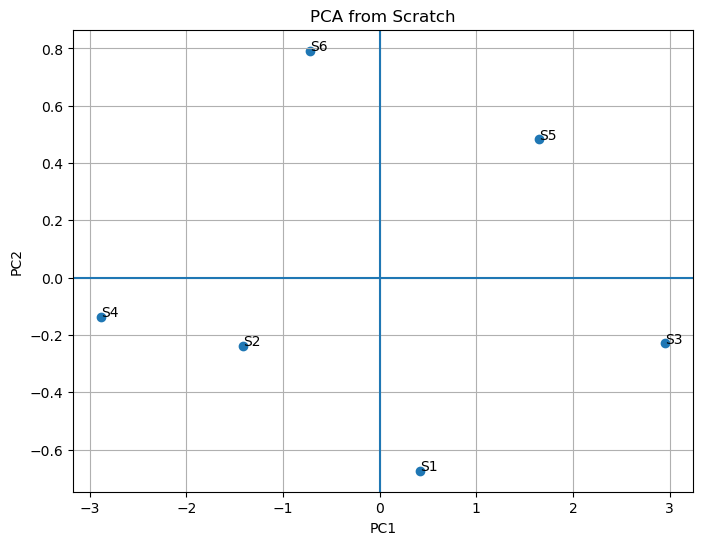

In [26]:
plt.figure(figsize=(8, 6))

plt.scatter(
    pca_scratch_df["PC1"],
    pca_scratch_df["PC2"]
)

for student in students:
    plt.annotate(
        student,
        (
            pca_scratch_df.loc[student, "PC1"],
            pca_scratch_df.loc[student, "PC2"]
        )
    )

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA from Scratch")
plt.axhline(0)
plt.axvline(0)
plt.grid(True)
plt.show()

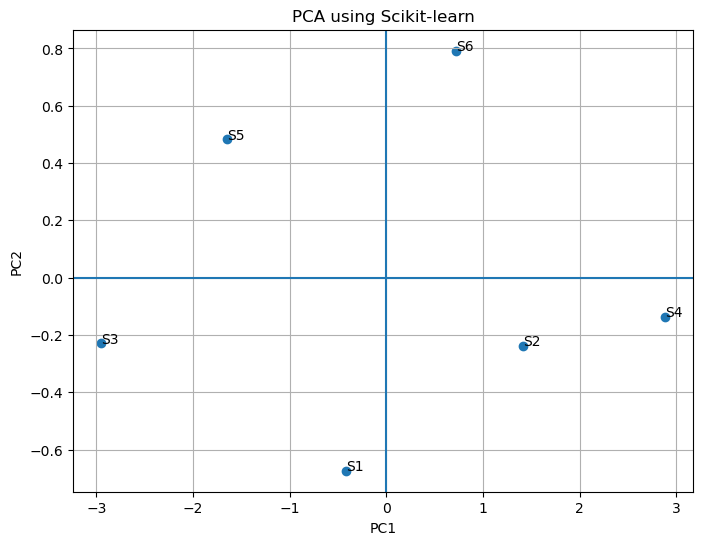

In [27]:
plt.figure(figsize=(8, 6))

plt.scatter(
    pca_sklearn_df["PC1"],
    pca_sklearn_df["PC2"]
)

for student in students:
    plt.annotate(
        student,
        (
            pca_sklearn_df.loc[student, "PC1"],
            pca_sklearn_df.loc[student, "PC2"]
        )
    )

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA using Scikit-learn")
plt.axhline(0)
plt.axvline(0)
plt.grid(True)
plt.show()

In [28]:
variance_retained = explained_variance_ratio[:2].sum() * 100

print(
    f"Variance retained by the first two components: "
    f"{variance_retained:.2f}%"
)

Variance retained by the first two components: 99.50%
